# Project 1. Кешбэк и отток подписок ПРАЙМ

## 1. Бизнес-вопрос и две стадии исследования

**Бизнес-вопрос.** Связано ли получение кешбэка владельцем подписки в предыдущем месяце с вероятностью отмены подписки в текущем месяце? За счёт чего изменился общий отток за период наблюдения?

**Гипотеза 1 (исходная).** Если владелец подписки получал кешбэк в предыдущем месяце, риск отмены подписки в текущем месяце ниже.

**Гипотеза 2 (исследовательская).** В снижении общего оттока между мартом 2025 и июлем 2026 вклад изменения ставок оттока внутри групп будет существенно больше вклада изменения долей групп с кешбэком и без него.

**Зерно расчёта:** одна строка - одна подписка * один месяц. Отток измеряется на уровне подписки; кешбэк учитываем по владельцу подписки.

**Период:** март 2025 - июль 2026. Для первого месяца используем февраль 2025 как период наблюдения кешбэка. Август 2026 не включаем: история отмен заканчивается в течение августа, поэтому это неполный месяц.

---

## 2. Подключение к базе

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sqlalchemy import text

# get_engine() живёт в вашем репозитории, в src/prime/config.py.
# Она читает строку подключения из .env — поэтому пароля здесь нет.
try:
    from prime.config import get_engine
except ModuleNotFoundError:
    raise ModuleNotFoundError(
        "Пакет prime не найден: ноутбук запущен не в окружении prime-monitor.\n"
        f"Сейчас Python отсюда: {sys.executable}\n"
        "JupyterLab: перейдите в корень prime-monitor и выполните uv run jupyter lab.\n"
        "VS Code: Select Kernel справа сверху -> .venv из папки prime-monitor."
    ) from None

engine = get_engine()


def q(sql: str, **params) -> pd.DataFrame:
    """Выполнить запрос и вернуть DataFrame. Соединение закрывается сразу."""
    try:
        with engine.connect() as conn:
            # Даты и месяцы считаем по UTC — так границы периода одинаковы.
            conn.execute(text("set time zone 'UTC'"))
            return pd.read_sql(text(sql), conn, params=params)
    finally:
        engine.dispose()


print("подключились как:", q("select current_user as login").iloc[0, 0])

подключились как: smsorokina


---

## 3. Аудит данных

Перед расчётами проверка покрытия истории и нескольких условий, от которых зависит результат

In [2]:
coverage = q("""
    select
        'subscription_started' as source,
        count(*) as n_rows,
        min(started_at)::date as first_date,
        max(started_at)::date as last_date
    from prime.subscriptions

    union all

    select
        'subscription_ended' as source,
        count(*) filter (where ended_at is not null) as n_rows,
        min(ended_at)::date as first_date,
        max(ended_at)::date as last_date
    from prime.subscriptions

    union all

    select
        'cashback_accrued' as source,
        count(*) as n_rows,
        min(accrued_at)::date as first_date,
        max(accrued_at)::date as last_date
    from prime.cashback
""")

display(coverage)

,source,n_rows,first_date,last_date
0,subscription_started,333905,2024-01-07,2026-08-29
1,subscription_ended,165927,2024-02-06,2026-08-28
2,cashback_accrued,2204058,2025-01-07,2026-09-05


In [3]:
subscription_audit = q("""
    select
        count(*) as subscriptions,
        count(distinct subscription_id) as unique_subscription_ids,
        count(*) filter (where ended_at is null) as active_now,
        count(*) filter (where ended_at < started_at) as end_before_start,
        count(*) filter (where ended_at is not null and cancel_reason is null) as ended_without_reason,
        count(*) filter (where c.client_id is null) as owner_missing_in_clients
    from prime.subscriptions s
    left join prime.clients c on c.client_id = s.owner_client_id
""")

cashback_audit = q("""
    select
        count(*) as cashback_rows,
        count(distinct b.cashback_id) as unique_cashback_ids,
        count(distinct b.transaction_id) as unique_transactions,
        count(*) filter (where b.bonus_amount <= 0) as nonpositive_bonus,
        count(*) filter (where t.transaction_id is null) as transaction_not_found,
        count(*) filter (where t.transaction_id is not null and t.status <> 'success') as transaction_not_successful,
        count(*) filter (where t.occurred_at is not null and b.accrued_at < t.occurred_at) as accrued_before_transaction
    from prime.cashback b
    left join prime.transactions t on t.transaction_id = b.transaction_id
""")

print("Подписки:")
display(subscription_audit)
print("Начисления кешбэка:")
display(cashback_audit)

Подписки:


,subscriptions,unique_subscription_ids,active_now,end_before_start,ended_without_reason,owner_missing_in_clients
0,333905,333905,167978,0,0,0


Начисления кешбэка:


,cashback_rows,unique_cashback_ids,unique_transactions,nonpositive_bonus,transaction_not_found,transaction_not_successful,accrued_before_transaction
0,2204058,2204058,2204058,0,8597,0,0


В основной расчёт попадают положительные начисления кешбэка, связанные с успешными транзакциями владельца подписки. В аудите обнаружены начисления без соответствующей транзакции; они не могут быть отнесены к клиенту по имеющейся связи и поэтому не попадают в аналитическую агрегацию. 

---

## 4. Панель «подписка * месяц»

Отток - доля подписок, находившихся под риском на начало месяца и закончившихся в этом месяце. Признак кешбэка рассчитывается за предыдущий календарный месяц, чтобы начисление не появилось после отмены.

В выборку входят подписки, оформленные до начала предыдущего календарного месяца и остававшиеся активными на начало анализируемого месяца. Получается, что для каждого наблюдения есть календарное окно, в котором измеряется кешбэк.

Семейная подписка считается одной подпиской на уровне риска и отмены. Таблица `subscription_members` не присоединяется, так как она описывает участников, а не дополнительные подписки. Начисления кешбэка присоединяем с владельцем через `transactions.client_id`.


In [4]:
FIRST_MONTH = "2025-03-01"  # первый месяц, в котором измеряем отток
LAST_MONTH = "2026-07-01"    # последний полный месяц в истории


def load_panel(first: str = FIRST_MONTH, last: str = LAST_MONTH) -> pd.DataFrame:
    """Месяц × подписка: риск отмены, кешбэк в прошлом месяце и результат."""
    return q("""
        with months as (
            select generate_series(
                cast(:first as date),
                cast(:last as date),
                interval '1 month'
            )::date as month_start
        ),
        cashback_by_client_month as (
            select
                t.client_id,
                date_trunc('month', b.accrued_at)::date as cashback_month,
                count(*) as cashback_count,
                sum(b.bonus_amount) as cashback_amount
            from prime.cashback b
            join prime.transactions t
              on t.transaction_id = b.transaction_id
             and t.status = 'success'
            where b.bonus_amount > 0
              and b.accrued_at >= cast(:first as date) - interval '1 month'
              and b.accrued_at < cast(:last as date)
            group by 1, 2
        )
        select
            m.month_start,
            s.subscription_id,
            s.owner_client_id,
            s.tariff_id,
            s.started_at::date as started_at,
            s.ended_at::date as ended_at,
            s.cancel_reason,
            coalesce(c.acquisition_channel, 'без канала') as acquisition_channel,
            coalesce(cb.cashback_count, 0) as cashback_count,
            coalesce(cb.cashback_amount, 0) as cashback_amount,
            (s.ended_at is not null
             and s.ended_at >= m.month_start
             and s.ended_at < m.month_start + interval '1 month') as churned
        from months m
        join prime.subscriptions s
          on s.started_at < m.month_start - interval '1 month'
         and (s.ended_at is null or s.ended_at >= m.month_start)
        left join prime.clients c
          on c.client_id = s.owner_client_id
        left join cashback_by_client_month cb
          on cb.client_id = s.owner_client_id
         and cb.cashback_month = (m.month_start - interval '1 month')::date
        order by m.month_start, s.subscription_id
    """, first=first, last=last)


panel = load_panel()
print(f"Строк в панели: {len(panel):,}")
display(panel.head(5))

Строк в панели: 2,394,469


,month_start,subscription_id,owner_client_id,tariff_id,started_at,ended_at,cancel_reason,acquisition_channel,cashback_count,cashback_amount,churned
0,2025-03-01,000189ec-1ec0-496d-b990-e9a41723ae68,f55b5629-2010-4c4d-8c78-636cfbbfe53a,1,2025-01-25,None,NaN,organic,0,0.00,False
1,2025-03-01,0001b6c7-9e49-4411-bbbd-23cc0c113706,604c9680-5d5d-4c9b-b2fe-0f8dd05c075a,1,2024-10-14,2025-06-11,too_expensive,performance,1,2.66,False
2,2025-03-01,00023468-47d5-4dba-95f2-70b2c9ae4a38,6c97636e-8ca9-4788-8b45-6c92f2ccd3e3,1,2024-09-15,2026-08-06,payment_failed,performance,1,20.95,False
3,2025-03-01,000301db-25eb-4967-aae0-83dd8421b967,5acfb208-8081-44b8-8f9d-188c0ca918fc,1,2024-03-11,2025-04-05,not_using,crm,0,0.00,False
4,2025-03-01,00037182-9519-43db-a9bc-82a54c8fdca0,754d381b-aaea-4669-b3ee-c890c575b5a2,1,2024-07-16,2025-03-13,payment_failed,organic,0,0.00,True


In [17]:
# Аудит панели: зерно должно быть ровно «одна подписка × один месяц».
for col in ["month_start", "started_at", "ended_at"]:
    panel[col] = pd.to_datetime(panel[col])

panel["cashback_amount"] = pd.to_numeric(panel["cashback_amount"], errors="coerce").fillna(0)
panel["churned"] = panel["churned"].astype(bool)

duplicate_rows = panel.duplicated(["subscription_id", "month_start"]).sum()
print("Дублей по ключу подписка * месяц:", duplicate_rows)
print("Месяцев:", panel["month_start"].nunique())
print("Подписок в панели:", panel["subscription_id"].nunique())
print("Отмен в текущем месяце:", int(panel["churned"].sum()))

assert duplicate_rows == 0, "Нарушено зерно: подписка повторяется в одном месяце"
assert panel["month_start"].min() == pd.Timestamp(FIRST_MONTH)
assert panel["month_start"].max() == pd.Timestamp(LAST_MONTH)
assert panel["churned"].notna().all()

# Факторы для сравнения: тариф, стаж подписки и канал привлечения.
panel["tariff_name"] = panel["tariff_id"].map({1: "Базовый", 2: "Расширенный"}).fillna("Неизвестный")
panel["cashback_group"] = np.where(
    panel["cashback_count"] > 0,
    "Был кешбэк",
    "Без кешбэка"
)
GROUPS = ["Без кешбэка", "Был кешбэк"]
panel["cashback_group"] = pd.Categorical(
    panel["cashback_group"], categories=GROUPS, ordered=True
)

panel["tenure_days"] = (panel["month_start"] - panel["started_at"]).dt.days
panel["tenure_group"] = pd.cut(
    panel["tenure_days"],
    bins=[0, 90, 180, 365, np.inf],
    right=False,
    labels=["до 3 мес.", "3-6 мес.", "6-12 мес.", "12+ мес."]
)
panel["cashback_intensity"] = np.select(
    [
        panel["cashback_count"].eq(0),
        panel["cashback_count"].between(1, 2),
        panel["cashback_count"].ge(3),
    ],
    ["Нет начислений", "1-2 начисления", "3+ начисления"],
    default="Проверить"
)

display(panel[[
    "month_start", "subscription_id", "tariff_name", "acquisition_channel",
    "tenure_days", "cashback_count", "cashback_amount", "churned"
]].head(10))

Дублей по ключу подписка * месяц: 0
Месяцев: 17
Подписок в панели: 265442
Отмен в текущем месяце: 94969


,month_start,subscription_id,tariff_name,acquisition_channel,tenure_days,cashback_count,cashback_amount,churned
0,2025-03-01,000189ec-1ec0-496d-b990-e9a41723ae68,Базовый,organic,35,0,0.00,False
1,2025-03-01,0001b6c7-9e49-4411-bbbd-23cc0c113706,Базовый,performance,138,1,2.66,False
2,2025-03-01,00023468-47d5-4dba-95f2-70b2c9ae4a38,Базовый,performance,167,1,20.95,False
3,2025-03-01,000301db-25eb-4967-aae0-83dd8421b967,Базовый,crm,355,0,0.00,False
4,2025-03-01,00037182-9519-43db-a9bc-82a54c8fdca0,Базовый,organic,228,0,0.00,True
5,2025-03-01,00037e10-95a7-4087-98ed-f25a270a1fc4,Базовый,partner_telecom,417,0,0.00,False
6,2025-03-01,0003cdba-be51-4afe-8b29-903586750b15,Базовый,organic,51,0,0.00,False
7,2025-03-01,000464b5-089d-4420-a344-0c31f064fb8d,Расширенный,social,320,0,0.00,False
8,2025-03-01,0005490d-8d5d-4c08-b186-de89e7e032e8,Расширенный,performance,306,0,0.00,False
9,2025-03-01,00057bd7-3139-4a9c-883a-98650eb9c4bb,Базовый,organic,384,0,0.00,False


---

## 5. Основной результат: динамика оттока

In [18]:
monthly_group = (
    panel.groupby(["month_start", "cashback_group"], observed=True)
    .agg(
        subscriptions_at_risk=("subscription_id", "size"),
        cancellations=("churned", "sum")
    )
    .reset_index()
)
monthly_group["churn_rate"] = (
    monthly_group["cancellations"] / monthly_group["subscriptions_at_risk"]
)
monthly_group["churn_rate_%"] = 100 * monthly_group["churn_rate"]

print("Отток по месяцам и признаку кешбэка в предыдущем месяце:")
display(monthly_group.round({"churn_rate": 4, "churn_rate_%": 2}))

# Общий отток — контрольная метрика, рассчитанная напрямую по той же панели.
monthly_total = (
    panel.groupby("month_start", as_index=False)
    .agg(
        subscriptions_at_risk=("subscription_id", "size"),
        cancellations=("churned", "sum")
    )
)
monthly_total["churn_rate"] = (
    monthly_total["cancellations"] / monthly_total["subscriptions_at_risk"]
)
monthly_total["churn_rate_%"] = 100 * monthly_total["churn_rate"]

display(monthly_total.round({"churn_rate": 4, "churn_rate_%": 2}))

# H1: pooled descriptive comparison over all subscription-month observations.
h1_summary = (
    panel.groupby("cashback_group", observed=True)
    .agg(
        subscription_months=("subscription_id", "size"),
        cancellations=("churned", "sum")
    )
    .reindex(GROUPS)
)
h1_summary["churn_rate"] = h1_summary["cancellations"] / h1_summary["subscription_months"]
h1_summary["churn_rate_%"] = 100 * h1_summary["churn_rate"]

rate_no_cb = float(h1_summary.loc["Без кешбэка", "churn_rate"])
rate_cb = float(h1_summary.loc["Был кешбэк", "churn_rate"])
h1_difference_pp = 100 * (rate_cb - rate_no_cb)

print("H1. Сводное описательное сравнение:")
display(h1_summary[["subscription_months", "cancellations", "churn_rate_%"]].round(3))
print(f"Разница оттока (кешбэк - без кешбэка): {h1_difference_pp:.3f} п.п.")
print("Это описательная разница, а не оценка причинного эффекта; отдельный статистический тест здесь не проводится.")


Отток по месяцам и признаку кешбэка в предыдущем месяце:


,month_start,cashback_group,subscriptions_at_risk,cancellations,churn_rate,churn_rate_%
0,2025-03-01,Без кешбэка,69260,2818,0.0407,4.07
1,2025-03-01,Был кешбэк,28125,1177,0.0418,4.18
2,2025-04-01,Без кешбэка,71541,2884,0.0403,4.03
3,2025-04-01,Был кешбэк,31755,1290,0.0406,4.06
4,2025-05-01,Без кешбэка,76460,3233,0.0423,4.23
5,2025-05-01,Был кешбэк,33441,1372,0.0410,4.10
6,2025-06-01,Без кешбэка,79853,3261,0.0408,4.08
7,2025-06-01,Был кешбэк,35777,1432,0.0400,4.00
8,2025-07-01,Без кешбэка,84834,3460,0.0408,4.08
9,2025-07-01,Был кешбэк,36770,1484,0.0404,4.04


,month_start,subscriptions_at_risk,cancellations,churn_rate,churn_rate_%
0,2025-03-01,97385,3995,0.0410,4.10
1,2025-04-01,103296,4174,0.0404,4.04
2,2025-05-01,109901,4605,0.0419,4.19
3,2025-06-01,115630,4693,0.0406,4.06
4,2025-07-01,121604,4944,0.0407,4.07
5,2025-08-01,127140,5177,0.0407,4.07
6,2025-09-01,132574,5253,0.0396,3.96
7,2025-10-01,138103,5549,0.0402,4.02
8,2025-11-01,142683,5557,0.0389,3.89
9,2025-12-01,147966,5887,0.0398,3.98


H1. Сводное описательное сравнение:


,subscription_months,cancellations,churn_rate_%
cashback_group,,,
Без кешбэка,1668420,66337,3.976
Был кешбэк,726049,28632,3.944


Разница оттока (кешбэк - без кешбэка): -0.033 п.п.
Это описательная разница, а не оценка причинного эффекта; отдельный статистический тест здесь не проводится.


### График 1. Отток по группам кешбэка во времени

График показывает, сохраняется ли различие от месяца к месяцу.

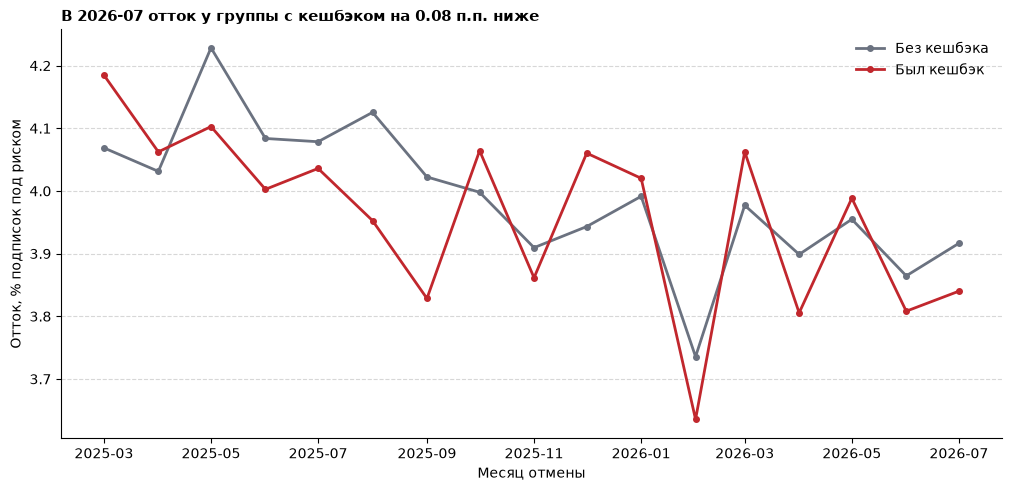

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
colors = {"Без кешбэка": "#6B7280", "Был кешбэк": "#C1272D"}

for group in GROUPS:
    frame = monthly_group[monthly_group["cashback_group"] == group].sort_values("month_start")
    ax.plot(
        frame["month_start"], frame["churn_rate_%"],
        marker="o", linewidth=2, markersize=4,
        color=colors[group], label=group
    )

last_month = monthly_group["month_start"].max()
last_rows = monthly_group[monthly_group["month_start"] == last_month].set_index("cashback_group")
last_diff_pp = last_rows.loc["Был кешбэк", "churn_rate_%"] - last_rows.loc["Без кешбэка", "churn_rate_%"]
direction = "выше" if last_diff_pp > 0 else "ниже"
ax.set_title(
    f"В {last_month:%Y-%m} отток у группы с кешбэком на {abs(last_diff_pp):.2f} п.п. {direction}",
    loc="left", fontsize=11, fontweight="bold"
)
ax.set_xlabel("Месяц отмены")
ax.set_ylabel("Отток, % подписок под риском")
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

---

## 6. Проверка альтернативного объяснения: тариф, стаж и канал

Сырые уровни оттока могут различаться из-за состава групп. Поэтому сравниваем отток внутри сочетаний месяц * тариф * стаж * канал привлечения. Включаем только страты, где в обеих группах достаточно наблюдений и порог указан в коде.

Это сопоставление уменьшает часть очевидных различий между группами, но не является причинной оценкой: возможны другие неучтённые факторы. Положительная разница означает более высокий отток в группе с кешбэком, отрицательная - более низкий.


In [19]:
strata_keys = ["month_start", "tariff_name", "tenure_group", "acquisition_channel"]
MIN_N_PER_GROUP = 100

strata = (
    panel.groupby(strata_keys + ["cashback_group"], observed=True, dropna=False)
    .agg(
        subscription_months=("subscription_id", "size"),
        cancellations=("churned", "sum")
    )
    .reset_index()
)
strata["churn_rate"] = strata["cancellations"] / strata["subscription_months"]

rates = strata.pivot(
    index=strata_keys, columns="cashback_group", values="churn_rate"
).reindex(columns=GROUPS)
counts = strata.pivot(
    index=strata_keys, columns="cashback_group", values="subscription_months"
).reindex(columns=GROUPS)

paired = rates.rename(columns={
    "Без кешбэка": "rate_no_cb",
    "Был кешбэк": "rate_cb"
}).join(counts.rename(columns={
    "Без кешбэка": "n_no_cb",
    "Был кешбэк": "n_cb"
}))

paired = paired.dropna(subset=["rate_no_cb", "rate_cb", "n_no_cb", "n_cb"]).copy()
paired = paired[
    (paired["n_no_cb"] >= MIN_N_PER_GROUP)
    & (paired["n_cb"] >= MIN_N_PER_GROUP)
].copy()

paired["difference_pp"] = 100 * (paired["rate_cb"] - paired["rate_no_cb"])
paired["weight"] = paired["n_no_cb"] + paired["n_cb"]
paired["weighted_difference"] = paired["difference_pp"] * paired["weight"]

print("Страт, где обе группы достаточно велики:", len(paired))
print("Минимальный размер группы в страте:", MIN_N_PER_GROUP)

adjusted = (
    paired.reset_index()
    .groupby(["tariff_name", "tenure_group"], observed=True, as_index=False)
    .agg(
        weighted_difference=("weighted_difference", "sum"),
        weight=("weight", "sum"),
        matched_strata=("difference_pp", "size")
    )
)
adjusted["difference_pp"] = adjusted["weighted_difference"] / adjusted["weight"]
adjusted = adjusted.sort_values(["tariff_name", "tenure_group"])

if paired.empty:
    print("Нет сопоставимых страт при выбранном пороге. Проверьте размеры групп; не снижайте порог без обоснования.")
else:
    print("Взвешенная разница оттока внутри сопоставимых страт, п.п. (кешбэк - без кешбэка):")
    display(adjusted[["tariff_name", "tenure_group", "matched_strata", "weight", "difference_pp"]].round(2))

Страт, где обе группы достаточно велики: 879
Минимальный размер группы в страте: 100
Взвешенная разница оттока внутри сопоставимых страт, п.п. (кешбэк - без кешбэка):


,tariff_name,tenure_group,matched_strata,weight,difference_pp
0,Базовый,до 3 мес.,102,206523,-0.01
1,Базовый,3-6 мес.,114,289821,-0.08
2,Базовый,6-12 мес.,119,491600,-0.02
3,Базовый,12+ мес.,114,491428,-0.09
4,Расширенный,до 3 мес.,102,126133,-0.08
5,Расширенный,3-6 мес.,102,173928,0.09
6,Расширенный,6-12 мес.,118,300381,0.07
7,Расширенный,12+ мес.,108,298998,0.01


### График 2. Разница оттока после сопоставления по доступным факторам

Положительное значение означает, что в сопоставимых стратах отток группы с кешбэком выше; отрицательное - ниже

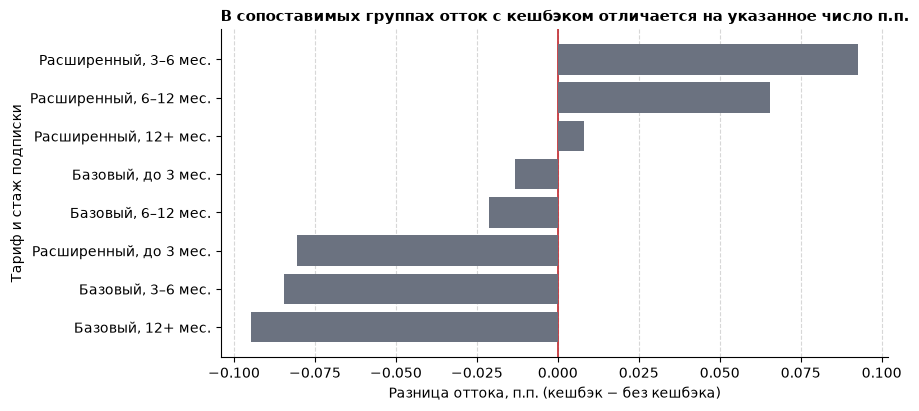

In [9]:
if not paired.empty:
    plot_data = adjusted.copy()
    plot_data["segment"] = plot_data["tariff_name"] + ", " + plot_data["tenure_group"].astype(str)
    plot_data = plot_data.sort_values("difference_pp")

    fig, ax = plt.subplots(figsize=(9, max(4, 0.42 * len(plot_data))), layout="constrained")
    ax.barh(plot_data["segment"], plot_data["difference_pp"], color="#6B7280", zorder=3)
    ax.axvline(0, color="#C1272D", linewidth=1.2)
    ax.set_title(
        "В сопоставимых группах отток с кешбэком отличается на указанное число п.п.",
        loc="left", fontsize=11, fontweight="bold"
    )
    ax.set_xlabel("Разница оттока, п.п. (кешбэк − без кешбэка)")
    ax.set_ylabel("Тариф и стаж подписки")
    ax.grid(axis="x", linestyle="--", alpha=0.5, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

---

## 7. Проверка интенсивности кешбэка и причин отмены

Это дополнительная проверка исходной гипотезы. Смотрим, меняется ли отток с числом начислений в предыдущем месяце, затем сравниваем структуру причин отмены среди реально отменённых подписок

In [ ]:
intensity_summary = (
    panel.groupby("cashback_intensity", observed=True)
    .agg(
        subscription_months=("subscription_id", "size"),
        cancellations=("churned", "sum")
    )
    .reset_index()
)
intensity_summary["churn_rate_%"] = 100 * intensity_summary["cancellations"] / intensity_summary["subscription_months"]
print("Отток по числу начислений кешбэка за предыдущий месяц:")
display(intensity_summary.round(2))

cancelled = panel.loc[panel["churned"]].copy()
cancelled["cancel_reason_clean"] = cancelled["cancel_reason"].fillna("Причина не указана")

reason_counts = (
    cancelled.groupby(["cashback_group", "cancel_reason_clean"], observed=True)
    .size()
    .rename("cancellations")
    .reset_index()
)
reason_counts["share_%"] = 100 * reason_counts["cancellations"] / reason_counts.groupby("cashback_group")["cancellations"].transform("sum")

reason_table = reason_counts.pivot(
    index="cancel_reason_clean", columns="cashback_group", values="share_%"
).reindex(columns=GROUPS).fillna(0)
print("Причины отмены, доля среди отмен в каждой группе, %:")
display(reason_table.round(2))

Отток по числу начислений кешбэка за предыдущий месяц:


,cashback_intensity,subscription_months,cancellations,churn_rate_%
0,1–2 начисления,644646,25382,3.94
1,3+ начисления,81403,3250,3.99
2,Нет начислений,1668420,66337,3.98


Причины отмены: доля среди отмен в каждой группе, %:


cashback_group,Без кешбэка,Был кешбэк
cancel_reason_clean,,
not_using,34.05,34.00
other,9.89,10.14
payment_failed,13.87,13.84
switched,17.86,18.16
too_expensive,24.33,23.86


### График 3. Структура причин отмены

Сравниваем доли причин внутри каждой группы.

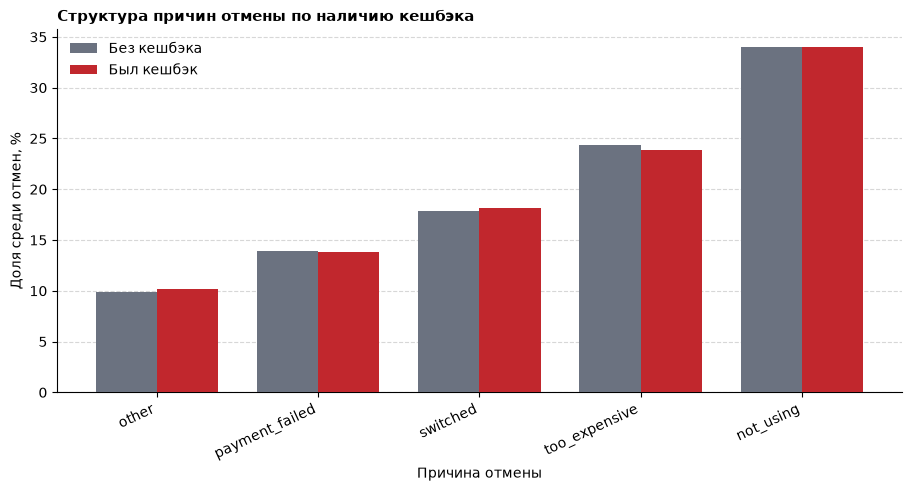

In [15]:
reason_plot = reason_table.sort_values(by=GROUPS, ascending=True)
x = np.arange(len(reason_plot))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
ax.bar(x - width / 2, reason_plot["Без кешбэка"], width, label="Без кешбэка", color="#6B7280", zorder=3)
ax.bar(x + width / 2, reason_plot["Был кешбэк"], width, label="Был кешбэк", color="#C1272D", zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(reason_plot.index, rotation=25, ha="right")
ax.set_title("Структура причин отмены по наличию кешбэка", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("Причина отмены")
ax.set_ylabel("Доля среди отмен, %")
ax.grid(axis="y", linestyle="--", alpha=0.5, zorder=0)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

---

## 8. Факторная декомпозиция изменения оттока

**Гипотеза 2 (исследовательская).** В снижении общего оттока между первым и последним месяцами периода вклад изменения оттока внутри групп с кешбэком и без него будет существенно больше вклада изменения долей этих групп.

Общий отток - это взвешенная сумма двух групповых уровней:

\[
R_t = w_{0,t}r_{0,t} + w_{1,t}r_{1,t},
\]

где \(r\) - отток внутри группы, а \(w\) - доля группы среди подписок под риском.

Для сравнения марта 2025 года и июля 2026 года сначала меняем групповые ставки при старых долях, затем меняем доли при новых ставках. Вклад структуры показывает только арифметическое влияние изменения долей двух групп и не доказывает причинный эффект кешбэка.


In [20]:
# Групповые ставки и веса из одной и той же панели.
rates_month = monthly_group.pivot(
    index="month_start", columns="cashback_group", values="churn_rate"
).reindex(columns=GROUPS)

counts_month = monthly_group.pivot(
    index="month_start", columns="cashback_group", values="subscriptions_at_risk"
).reindex(columns=GROUPS).fillna(0)

cancel_month = monthly_group.pivot(
    index="month_start", columns="cashback_group", values="cancellations"
).reindex(columns=GROUPS).fillna(0)

weights_month = counts_month.div(counts_month.sum(axis=1), axis=0)
overall_month = cancel_month.sum(axis=1) / counts_month.sum(axis=1)
reconstructed = (weights_month * rates_month).sum(axis=1)

# Контроль: средневзвешенный отток групп должен совпасть с общим оттоком.
assert np.allclose(reconstructed, overall_month, equal_nan=False), "Группы не сходятся с общим оттоком"
assert (counts_month > 0).all().all(), "В одном из месяцев отсутствует одна из групп"

# Дополнительная диагностика: декомпозиция каждого последовательного перехода.
transition_rows = []
for i in range(1, len(rates_month)):
    month0 = rates_month.index[i - 1]
    month1 = rates_month.index[i]

    w0 = weights_month.loc[month0]
    w1 = weights_month.loc[month1]
    r0 = rates_month.loc[month0]
    r1 = rates_month.loc[month1]

    within_effect = sum(w0[g] * (r1[g] - r0[g]) for g in GROUPS)
    structure_effect = sum(r1[g] * (w1[g] - w0[g]) for g in GROUPS)
    actual_change = overall_month.loc[month1] - overall_month.loc[month0]

    assert np.isclose(within_effect + structure_effect, actual_change, atol=1e-10), (
        f"Влияния не сходятся: {month0:%Y-%m} -> {month1:%Y-%m}"
    )

    transition_rows.append({
        "month": month1,
        "churn_before_%": 100 * overall_month.loc[month0],
        "churn_after_%": 100 * overall_month.loc[month1],
        "change_pp": 100 * actual_change,
        "within_group_effect_pp": 100 * within_effect,
        "group_mix_effect_pp": 100 * structure_effect,
    })

transition_decomposition = pd.DataFrame(transition_rows)
print("Контроль декомпозиции последовательных месяцев (первые переходы):")
display(transition_decomposition.head(8).round({
    "churn_before_%": 3,
    "churn_after_%": 3,
    "change_pp": 3,
    "within_group_effect_pp": 3,
    "group_mix_effect_pp": 3,
}))

# H2 / исследовательский вопрос 2: декомпозиция изменения за весь период.
start_month = overall_month.index.min()
end_month = overall_month.index.max()
w_start = weights_month.loc[start_month]
w_end = weights_month.loc[end_month]
r_start = rates_month.loc[start_month]
r_end = rates_month.loc[end_month]

overall_start = float(overall_month.loc[start_month])
overall_end = float(overall_month.loc[end_month])
overall_change_pp = 100 * (overall_end - overall_start)
within_effect_pp = 100 * sum(w_start[g] * (r_end[g] - r_start[g]) for g in GROUPS)
structure_effect_pp = 100 * sum(r_end[g] * (w_end[g] - w_start[g]) for g in GROUPS)

endpoint_decomposition = pd.DataFrame({
    "component": ["Фактическое изменение общего оттока", "Изменение ставок внутри групп", "Изменение долей групп"],
    "contribution_pp": [overall_change_pp, within_effect_pp, structure_effect_pp],
})

assert np.isclose(within_effect_pp + structure_effect_pp, overall_change_pp, atol=1e-8), (
    "Сумма факторов не равна изменению общего оттока за период"
)

print(f"Период сравнения: {start_month:%Y-%m} -> {end_month:%Y-%m}")
print(f"Общий отток: {100 * overall_start:.3f}% -> {100 * overall_end:.3f}%")
print(f"Изменение общего оттока: {overall_change_pp:.3f} п.п.")
print("Декомпозиция за весь период:")
display(endpoint_decomposition.round({"contribution_pp": 3}))
print("Проверка пройдена: сумма вкладов равна общему изменению.")


Контроль декомпозиции последовательных месяцев (первые переходы):


,month,churn_before_%,churn_after_%,change_pp,within_group_effect_pp,group_mix_effect_pp
0,2025-04-01,4.102,4.041,-0.061,-0.062,0.001
1,2025-05-01,4.041,4.190,0.149,0.149,0.000
2,2025-06-01,4.190,4.059,-0.131,-0.131,-0.000
3,2025-07-01,4.059,4.066,0.007,0.007,0.000
4,2025-08-01,4.066,4.072,0.006,0.008,-0.001
5,2025-09-01,4.072,3.962,-0.110,-0.110,0.000
6,2025-10-01,3.962,4.018,0.056,0.056,-0.000
7,2025-11-01,4.018,3.895,-0.123,-0.123,-0.000


Период сравнения: 2025-03 -> 2026-07
Общий отток: 4.102% -> 3.893%
Изменение общего оттока: -0.209 п.п.
Декомпозиция за весь период:


,component,contribution_pp
0,Фактическое изменение общего оттока,-0.209
1,Изменение ставок внутри групп,-0.208
2,Изменение долей групп,-0.001


Проверка пройдена: сумма вкладов равна общему изменению.


### График 4. Из чего складывается изменение оттока за весь период

На графике сравнили фактическое изменение общего оттока и два его арифметических компонента. Если вклад изменения долей групп близок к нулю, то сдвиг состава групп мало объясняет динамику показателя.

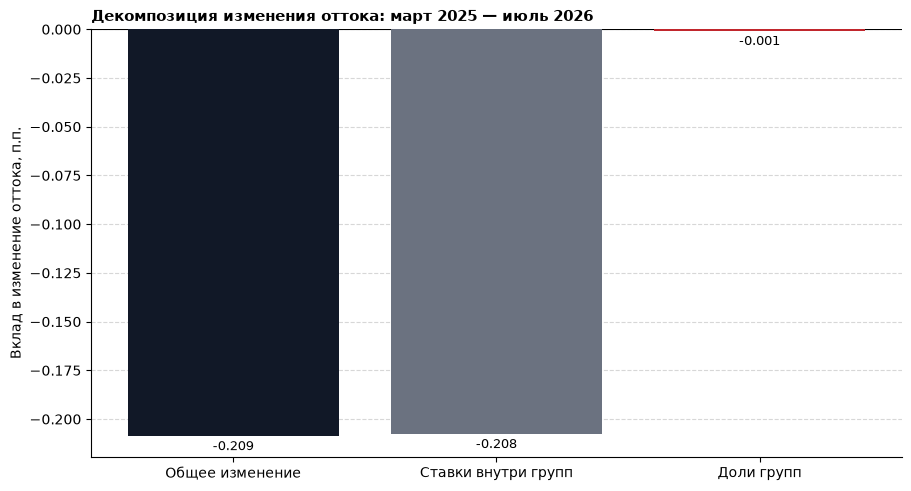

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
plot_decomp = endpoint_decomposition.copy()
labels = [
    "Общее изменение",
    "Ставки внутри групп",
    "Доли групп",
]
values = plot_decomp["contribution_pp"].to_numpy()
colors = ["#111827", "#6B7280", "#C1272D"]
bars = ax.bar(labels, values, color=colors, zorder=3)
ax.axhline(0, color="black", linewidth=0.8)
ax.bar_label(bars, labels=[f"{v:+.3f}" for v in values], padding=3, fontsize=9)
ax.set_title("Декомпозиция изменения оттока: март 2025 — июль 2026", loc="left", fontsize=11, fontweight="bold")
ax.set_ylabel("Вклад в изменение оттока, п.п.")
ax.grid(axis="y", linestyle="--", alpha=0.5, zorder=0)
ax.spines[["top", "right"]].set_visible(False)
plt.show()


---

## 9. Вывод и рекомендация

### Гипотеза 1, исходная

Предполагалось, что получение кешбэка владельцем подписки в предыдущем месяце связано со снижением вероятности отмены в текущем месяце. В аналитической выборке отток составил 3,976% без начислений и 3,944% с начислениями кешбэка. Разница - около 0,033 процентного пункта. После сопоставления по месяцу, тарифу, стажу и каналу привлечения устойчивого однонаправленного различия не обнаружено. Таким образом, первоначальная гипотеза не получила убедительной поддержки в описательных данных.

### Гипотеза 2, исследовательская

Исследовательская декомпозиция показала, что общий отток снизился с 4,102% в марте 2025 года до 3,893% в июле 2026 года. Из общего изменения на -0,209 процентного пункта вклад изменения ставок внутри групп составил -0,208 пункта, а вклад изменения долей групп составил -0,001 пункта. Следовательно, изменение состава групп с кешбэком и без него практически не объясняет динамику общего оттока.

### Ограничения

Исследование получилось наблюдательным и не установило причинного эффекта кешбэка.

### Рекомендация

На основании проведённого анализа не рекомендую увеличение расходов на кешбэк ради снижения оттока.

In [14]:
# Краткий итог для записки: формируется из фактических результатов запуска.

print("H1 — исходная гипотеза")
print(f"Отток без кешбэка: {100 * rate_no_cb:.3f}%")
print(f"Отток с кешбэком:   {100 * rate_cb:.3f}%")
print(f"Разница (кешбэк − без кешбэка): {h1_difference_pp:+.3f} п.п.")
print("Интерпретация: это описательное сравнение; оно не доказывает причинный эффект кешбэка.")

print("\nВопрос 2 — изменение общего оттока")
print(f"{start_month:%Y-%m}: {100 * overall_start:.3f}%")
print(f"{end_month:%Y-%m}: {100 * overall_end:.3f}%")
print(f"Общее изменение: {overall_change_pp:+.3f} п.п.")
print(f"Вклад изменения ставок внутри групп: {within_effect_pp:+.3f} п.п.")
print(f"Вклад изменения долей групп: {structure_effect_pp:+.3f} п.п.")
print("Проверка декомпозиции:", np.isclose(within_effect_pp + structure_effect_pp, overall_change_pp, atol=1e-8))

H1 — исходная гипотеза
Отток без кешбэка: 3.976%
Отток с кешбэком:   3.944%
Разница (кешбэк − без кешбэка): -0.033 п.п.
Интерпретация: это описательное сравнение; оно не доказывает причинный эффект кешбэка.

Вопрос 2 — изменение общего оттока
2025-03: 4.102%
2026-07: 3.893%
Общее изменение: -0.209 п.п.
Вклад изменения ставок внутри групп: -0.208 п.п.
Вклад изменения долей групп: -0.001 п.п.
Проверка декомпозиции: True
